Importing the libraries

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from imblearn.under_sampling import RandomUnderSampler


Reading the data


In [56]:
dataset = pd.read_csv("/content/drive/MyDrive/CSE422_dataset/12.csv")
dataset.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [30]:
dataset.shape

(5110, 12)

In [31]:
dataset.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


<Axes: xlabel='bmi', ylabel='Count'>

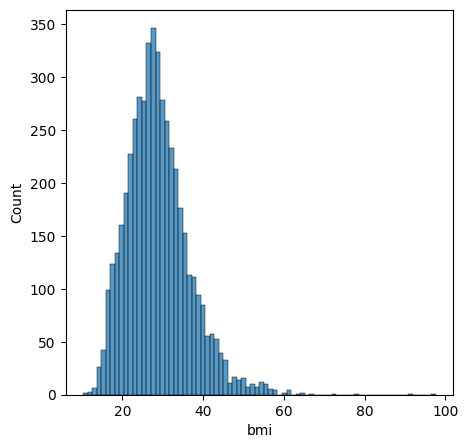

In [32]:
fig, ax = plt.subplots(figsize = (5,5))
sns.histplot(dataset.bmi)

In [33]:
dataset.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


In [34]:
dataset['stroke'].value_counts()

,count
stroke,
0,4861
1,249


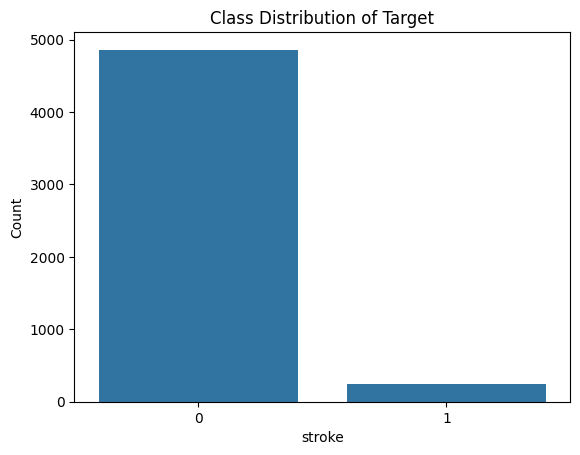

In [58]:
sns.countplot(x="stroke", data=dataset)
plt.title("Class Distribution of Target")
plt.xlabel("stroke")
plt.ylabel("Count")
plt.show()

In [35]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [36]:
dataset.loc[dataset.duplicated(subset = ['id'])]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke


So the data is skewed and the dataset is imbalanced. There are no duplicates. I need to drop the id column. Need to split into train test and then impute bmi values. Also need to see the correlation matrix to figure out which features are relevant


removed 1 anomaly row

In [37]:
dataset['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


In [38]:
dataset = dataset[dataset['gender'] != 'Other']
dataset.shape


(5109, 12)

In [39]:
dataset['Residence_type'].value_counts()

,count
Residence_type,
Urban,2596
Rural,2513


In [40]:
dataset.nunique()

,0
id,5109
gender,2
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3978
bmi,418


In [41]:
dataset = dataset.drop(columns = ['id'], axis = 1)

Univariate EDA

In [42]:
dataset.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [43]:
dataset['gender'] = dataset['gender'].map({'Male':0, 'Female': 1})
dataset['ever_married'] = dataset['ever_married'].map({'Yes': 1, 'No':0})
dataset['Residence_type'] = dataset['Residence_type'].map({'Urban':1, 'Rural':0})

In [44]:
dataset.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,1,61.0,0,0,1,Self-employed,0,202.21,NaN,never smoked,1
2,0,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
3,1,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
4,1,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1


Now one hot encoding on work_type and smoking_status


In [45]:
df_encoded = pd.get_dummies(dataset, columns = ['work_type', 'smoking_status'], dtype = int)
df_encoded

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,0,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,0,1,0,0
1,1,61.0,0,0,1,0,202.21,NaN,1,0,0,0,1,0,0,0,1,0
2,0,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,0,1,0
3,1,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,0,1
4,1,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,1,80.0,1,0,1,1,83.75,NaN,0,0,0,1,0,0,0,0,1,0
5106,1,81.0,0,0,1,1,125.20,40.0,0,0,0,0,1,0,0,0,1,0
5107,1,35.0,0,0,1,0,82.99,30.6,0,0,0,0,1,0,0,0,1,0
5108,0,51.0,0,0,1,0,166.29,25.6,0,0,0,1,0,0,0,1,0,0


=== Spearman Correlation Matrix ===
                        age  avg_glucose_level       bmi
age                1.000000           0.145360  0.375441
avg_glucose_level  0.145360           1.000000  0.114633
bmi                0.375441           0.114633  1.000000


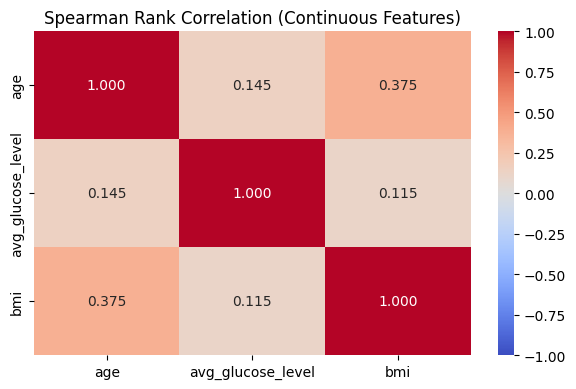

In [46]:
df_numerical = df_encoded[['age', 'avg_glucose_level', 'bmi']]
spearman_corr = df_numerical.corr(method='spearman')

print("=== Spearman Correlation Matrix ===")
print(spearman_corr)

# 3. Generate a Heatmap for your project report
plt.figure(figsize=(6, 4))
sns.heatmap(
    spearman_corr,
    annot=True,        # Displays the actual correlation numbers
    cmap='coolwarm',   # Color gradient (blue for negative, red for positive)
    vmin=-1, vmax=1,   # Locks the scale from -1 to 1
    fmt=".3f"          # Rounds to 3 decimal places
)
plt.title('Spearman Rank Correlation (Continuous Features)')
plt.tight_layout()
plt.show()

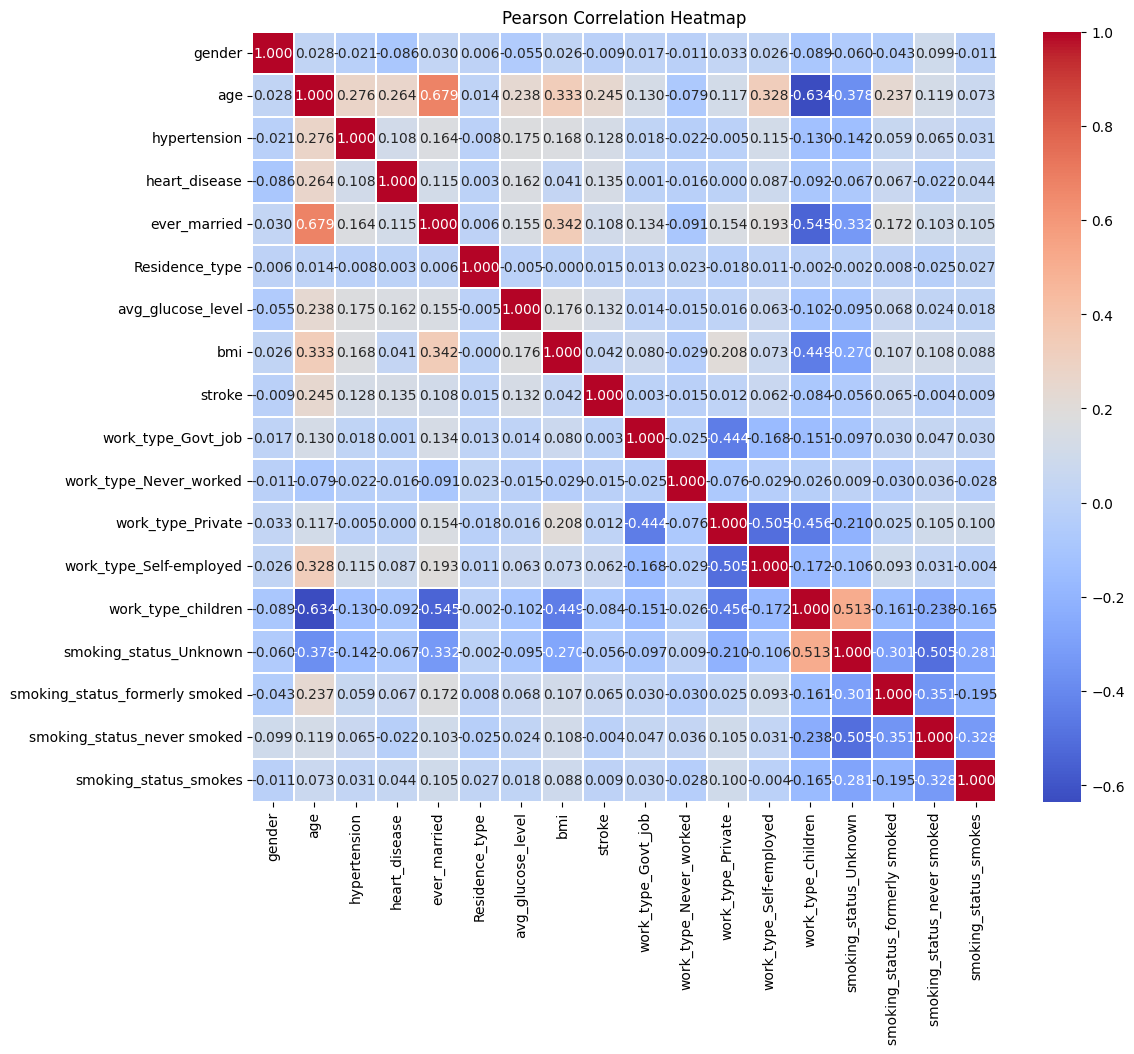

In [47]:
df_corr = df_encoded.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(df_corr, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.title("Pearson Correlation Heatmap")
plt.show()

In [48]:
numeric_cols = dataset[['age' ,'avg_glucose_level', 'bmi', 'stroke']]
numeric_cols.skew()

,0
age,-0.137430
avg_glucose_level,1.572815
bmi,1.055063
stroke,4.192807


<Axes: xlabel='avg_glucose_level'>

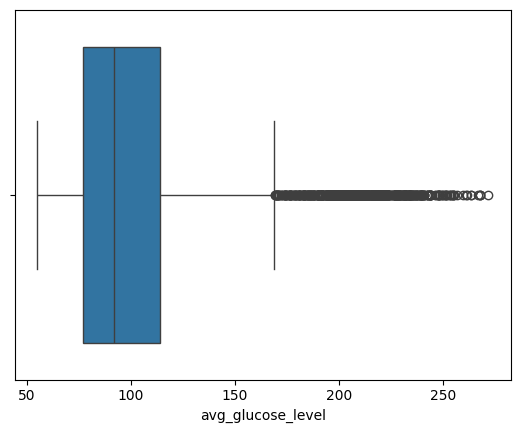

In [49]:
sns.boxplot(data=df_encoded, x="avg_glucose_level")

<Axes: xlabel='bmi'>

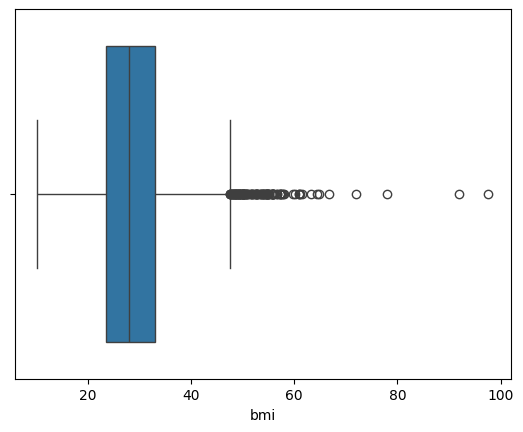

In [50]:
sns.boxplot(data=df_encoded, x="bmi")

In [51]:
df_encoded = df_encoded.drop(columns = ['gender', 'ever_married', 'bmi', 'work_type_children', 'work_type_Private','work_type_Self-employed', 'work_type_Govt_job', 'work_type_Never_worked', 'smoking_status_Unknown'], axis = 1)

**PRE PROCESSING**

K-Fold, Training, Evaluation, &  Visualization
Processing Fold 1...
Class balance BEFORE undersampling:
stroke
0    3888
1     199
Name: count, dtype: int64

Class balance AFTER undersampling:
stroke
0    199
1    199
Name: count, dtype: int64
Processing Fold 2...
Class balance BEFORE undersampling:
stroke
0    3888
1     199
Name: count, dtype: int64

Class balance AFTER undersampling:
stroke
0    199
1    199
Name: count, dtype: int64
Processing Fold 3...
Class balance BEFORE undersampling:
stroke
0    3888
1     199
Name: count, dtype: int64

Class balance AFTER undersampling:
stroke
0    199
1    199
Name: count, dtype: int64
Processing Fold 4...
Class balance BEFORE undersampling:
stroke
0    3888
1     199
Name: count, dtype: int64

Class balance AFTER undersampling:
stroke
0    199
1    199
Name: count, dtype: int64
Processing Fold 5...
Class balance BEFORE undersampling:
stroke
0    3888
1     200
Name: count, dtype: int64

Class balance AFTER undersampling:
stroke
0    200
1  

,Accuracy,Precision,Recall,F1 Score,AUC Score,PR-AUC Score
Logistic Regression,0.6721,0.1175,0.8753,0.2070,0.8380,0.1955
KNN,0.6310,0.1071,0.8834,0.1906,0.8110,0.1493
Neural Network,0.6851,0.1182,0.8429,0.2072,0.8319,0.1855
K-Means (Unsupervised),0.8444,0.1342,0.4020,0.2012,0.6345,0.0862


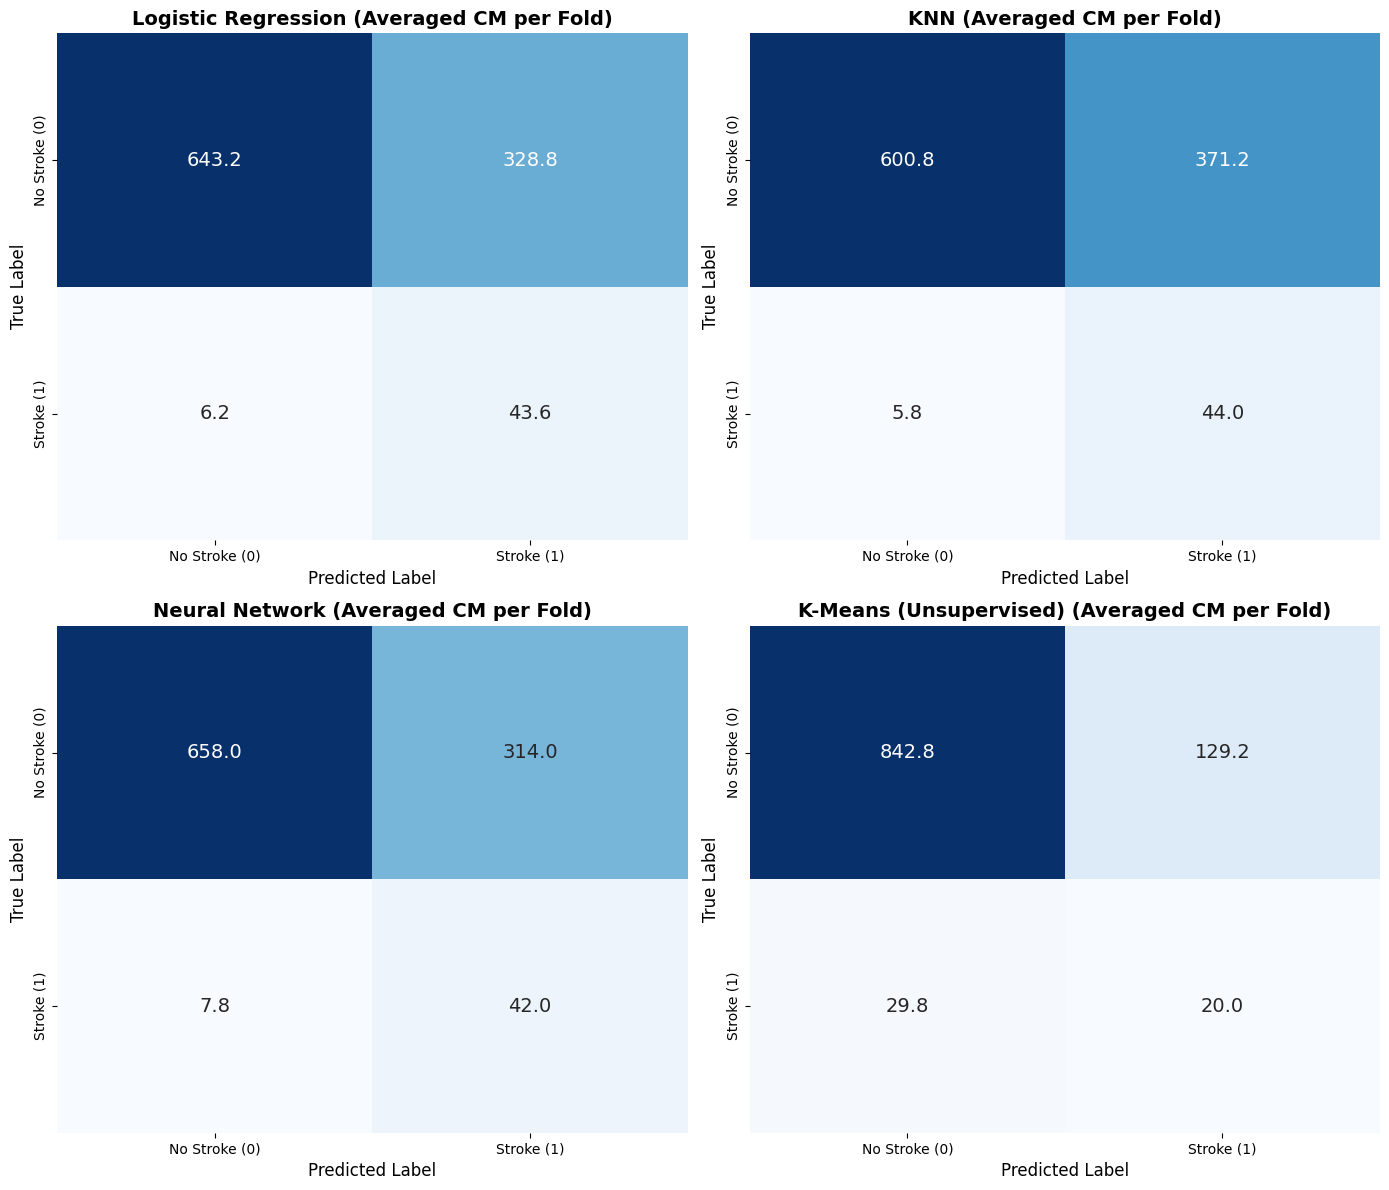

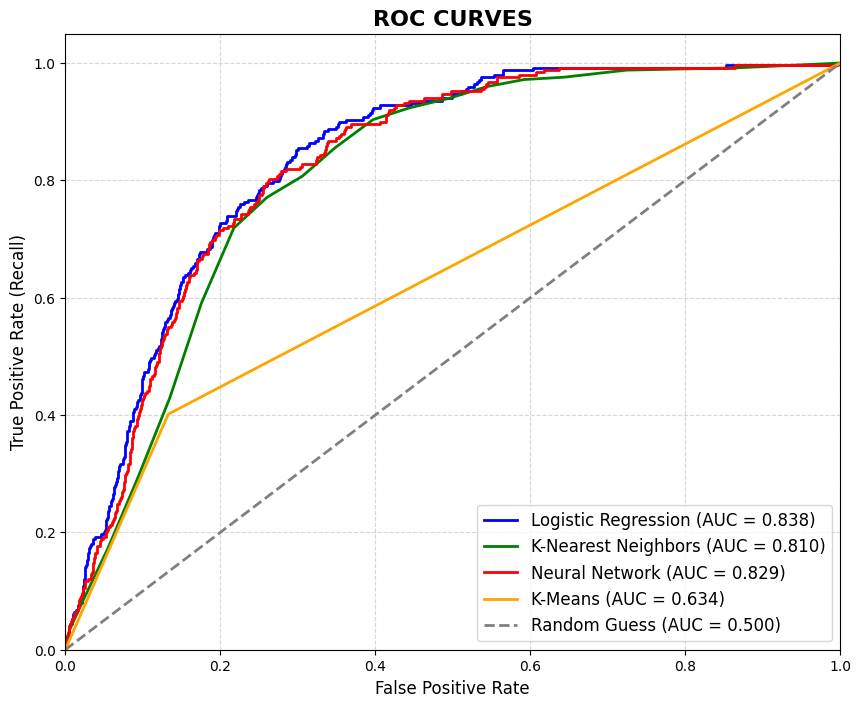

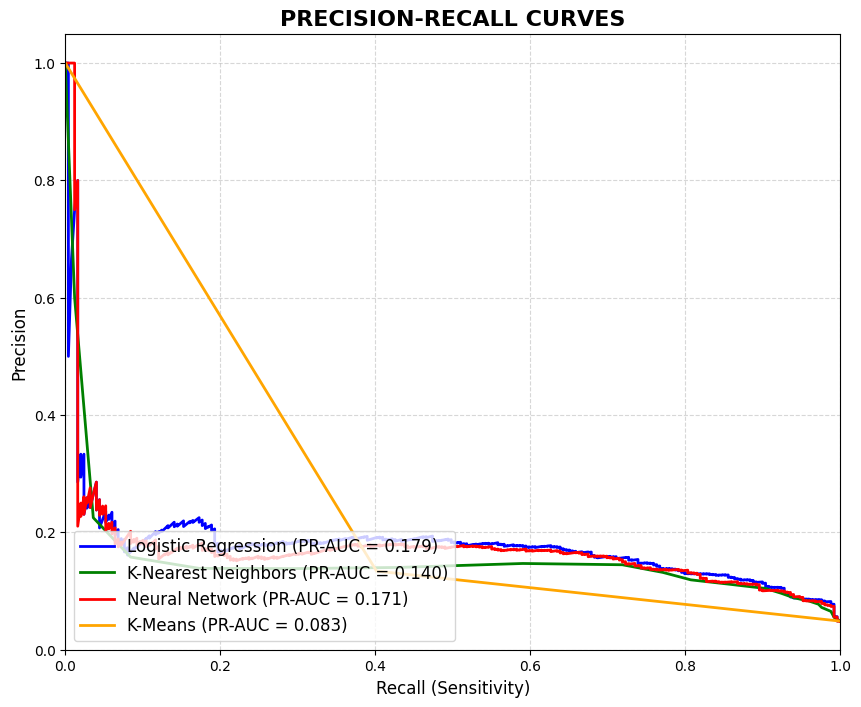

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, confusion_matrix, roc_curve, auc
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2
from sklearn.metrics import average_precision_score

print("K-Fold, Training, Evaluation, &  Visualization")

X = df_encoded.drop('stroke', axis=1)
y = df_encoded['stroke']

# 2. Setup K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_names = ['Logistic Regression', 'KNN', 'Neural Network', 'K-Means (Unsupervised)']
results = {name: {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'auc': [], 'pr_auc': []} for name in model_names}
fold_cms = {name: [] for name in model_names}
true_labels_all = []
lr_probs_all, knn_probs_all, nn_probs_all, km_probs_all = [], [], [], []

def get_optimal_predictions(y_train_true, y_train_prob, y_val_prob):
    # 1. Find the best threshold using TRAINING data
    precisions, recalls, thresholds = precision_recall_curve(y_train_true, y_train_prob)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]

    # 2. Apply that locked threshold to the VALIDATION data
    return (y_val_prob >= best_threshold).astype(int)

fold_no = 1
for train_index, val_index in skf.split(X, y):
    print(f"Processing Fold {fold_no}...")

    X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]

    numerical_cols = ['age', 'avg_glucose_level']

# Create a ColumnTransformer
# remainder='passthrough' tells it to leave all other columns (your binary ones) alone
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_cols)
        ],
        remainder='passthrough'
    )

# Fit on training data and transform
    X_train_scaled_array = preprocessor.fit_transform(X_train_fold)
    X_test_scaled_array = preprocessor.transform(X_val_fold)
    scaled_cols = numerical_cols + [col for col in X_train_fold.columns if col not in numerical_cols]

    X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=scaled_cols)
    X_val_scaled = pd.DataFrame(X_test_scaled_array, columns=scaled_cols)

    # Scale Data
#     imputer = KNNImputer(n_neighbors=5)

# # Fit on the scaled training data, transform both
#     X_train_scaled = pd.DataFrame(imputer.fit_transform(X_train_scaled), columns=scaled_cols)
#     X_val_scaled = pd.DataFrame(imputer.transform(X_val_scaled), columns=scaled_cols)

# # Verify the imputation worked
#     print("Missing BMI in Training Set:", X_train_scaled['bmi'].isnull().sum())
#     print("Missing BMI in Testing Set:", X_val_scaled['bmi'].isnull().sum())

    undersampler = RandomUnderSampler(random_state=42)

# 2. Fit and apply the undersampler ONLY to the pre-processed training data
# Ensure X_train_final has already been scaled and imputed
    X_train_res, y_train_res = undersampler.fit_resample(X_train_scaled, y_train_fold)

# 3. Verify the new class balance
    print("Class balance BEFORE undersampling:")
    print(y_train_fold.value_counts())

    print("\nClass balance AFTER undersampling:")
    print(y_train_res.value_counts())

    # Model 1: Logistic Regression
    lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    lr.fit(X_train_res, y_train_res)
    lr_train_prob = lr.predict_proba(X_train_res)[:, 1] # Get training probs
    lr_prob = lr.predict_proba(X_val_scaled)[:, 1]      # Get validation probs
    lr_pred = get_optimal_predictions(y_train_res, lr_train_prob, lr_prob)

    results['Logistic Regression']['acc'].append(accuracy_score(y_val_fold, lr_pred))
    results['Logistic Regression']['prec'].append(precision_score(y_val_fold, lr_pred, zero_division=0))
    results['Logistic Regression']['rec'].append(recall_score(y_val_fold, lr_pred))
    results['Logistic Regression']['f1'].append(f1_score(y_val_fold, lr_pred))
    results['Logistic Regression']['auc'].append(roc_auc_score(y_val_fold, lr_prob))
    results['Logistic Regression']['pr_auc'].append(average_precision_score(y_val_fold, lr_prob))
    fold_cms['Logistic Regression'].append(confusion_matrix(y_val_fold, lr_pred))
    lr_probs_all.extend(lr_prob)

    # Model 2: K-Nearest Neighbors (KNN)
    knn = KNeighborsClassifier(n_neighbors=19)
    knn.fit(X_train_res, y_train_res)

    knn_train_prob = knn.predict_proba(X_train_res)[:, 1]
    knn_prob = knn.predict_proba(X_val_scaled)[:, 1]
    knn_pred = get_optimal_predictions(y_train_res, knn_train_prob, knn_prob)

    results['KNN']['acc'].append(accuracy_score(y_val_fold, knn_pred))
    results['KNN']['prec'].append(precision_score(y_val_fold, knn_pred, zero_division=0))
    results['KNN']['rec'].append(recall_score(y_val_fold, knn_pred))
    results['KNN']['f1'].append(f1_score(y_val_fold, knn_pred))
    results['KNN']['auc'].append(roc_auc_score(y_val_fold, knn_prob))
    results['KNN']['pr_auc'].append(average_precision_score(y_val_fold, knn_prob))
    fold_cms['KNN'].append(confusion_matrix(y_val_fold, knn_pred))
    knn_probs_all.extend(knn_prob)

    # Model 3: Neural Network
    tf.random.set_seed(42)

    # Create an internal split purely for early stopping (20% of training fold)
    X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
        X_train_res, y_train_res, test_size=0.2, random_state=42, stratify=y_train_res
    )

    nn = Sequential([
        Input(shape=(X_train_res.shape[1],)),
        Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.2),
        Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])

    nn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
               loss='binary_crossentropy',
               metrics=['accuracy'])

    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

    # Train using the INTERNAL split, not X_val_scaled
    nn.fit(X_nn_train, y_nn_train,
           epochs=100,
           batch_size=16,
           validation_data=(X_nn_val, y_nn_val),
           callbacks=[early_stop],
           verbose=0)

    # Get predictions for thresholding
    nn_train_prob = nn.predict(X_train_res, verbose=0).flatten()
    nn_prob = nn.predict(X_val_scaled, verbose=0).flatten()
    nn_pred = get_optimal_predictions(y_train_res, nn_train_prob, nn_prob)

    results['Neural Network']['acc'].append(accuracy_score(y_val_fold, nn_pred))
    results['Neural Network']['prec'].append(precision_score(y_val_fold, nn_pred, zero_division=0))
    results['Neural Network']['rec'].append(recall_score(y_val_fold, nn_pred))
    results['Neural Network']['f1'].append(f1_score(y_val_fold, nn_pred))
    results['Neural Network']['auc'].append(roc_auc_score(y_val_fold, nn_prob))
    results['Neural Network']['pr_auc'].append(average_precision_score(y_val_fold, nn_prob))
    fold_cms['Neural Network'].append(confusion_matrix(y_val_fold, nn_pred))
    nn_probs_all.extend(nn_prob)

    # Model 4: K-Means (Unsupervised Baseline)
    kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
    kmeans.fit(X_train_scaled)

    # 2. Predict on the validation data
    train_km_pred = kmeans.predict(X_train_scaled)
    km_pred = kmeans.predict(X_val_scaled)
    if y_train_fold[train_km_pred == 0].mean() > y_train_fold[train_km_pred == 1].mean():
        km_pred = np.where(km_pred == 0, 1, 0)
    km_prob = km_pred

    results['K-Means (Unsupervised)']['acc'].append(accuracy_score(y_val_fold, km_pred))
    results['K-Means (Unsupervised)']['prec'].append(precision_score(y_val_fold, km_pred, zero_division=0))
    results['K-Means (Unsupervised)']['rec'].append(recall_score(y_val_fold, km_pred))
    results['K-Means (Unsupervised)']['f1'].append(f1_score(y_val_fold, km_pred))
    results['K-Means (Unsupervised)']['auc'].append(roc_auc_score(y_val_fold, km_prob))
    results['K-Means (Unsupervised)']['pr_auc'].append(average_precision_score(y_val_fold, km_prob))
    fold_cms['K-Means (Unsupervised)'].append(confusion_matrix(y_val_fold, km_pred))
    km_probs_all.extend(km_prob)

    true_labels_all.extend(y_val_fold)
    fold_no += 1

#Table of Final Results
final_metrics = {}
for name in model_names:
    final_metrics[name] = {
        'Accuracy': np.mean(results[name]['acc']),
        'Precision': np.mean(results[name]['prec']),
        'Recall': np.mean(results[name]['rec']),
        'F1 Score': np.mean(results[name]['f1']),
        'AUC Score': np.mean(results[name]['auc']),
        'PR-AUC Score': np.mean(results[name]['pr_auc'])
    }

comparison_df = pd.DataFrame(final_metrics).T
print("\n=== Final Comprehensive Model Comparison (Averaged across 5 Folds) ===")
display(comparison_df.round(4))

true_labels_all = np.array(true_labels_all)
lr_probs_all = np.array(lr_probs_all)
knn_probs_all = np.array(knn_probs_all)
nn_probs_all = np.array(nn_probs_all)
km_probs_all = np.array(km_probs_all)


# 5. Plotting Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, name in enumerate(model_names):
    # Average the confusion matrices across the 5 folds
    avg_cm = np.mean(fold_cms[name], axis=0)

    sns.heatmap(avg_cm, annot=True, fmt='.1f', cmap='Blues', ax=axes[i], cbar=False, annot_kws={"size": 14})
    axes[i].set_title(f'{name} (Averaged CM per Fold)', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=12)
    axes[i].set_ylabel('True Label', fontsize=12)
    axes[i].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
    axes[i].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

plt.tight_layout()
plt.show()

# Plotting ROC Curves==
plt.figure(figsize=(10, 8))

models_probs = [
    ('Logistic Regression', lr_probs_all, 'blue'),
    ('K-Nearest Neighbors', knn_probs_all, 'green'),
    ('Neural Network', nn_probs_all, 'red'),
    ('K-Means', km_probs_all, 'orange')
]

for name, y_prob, color in models_probs:
    fpr, tpr, _ = roc_curve(true_labels_all, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC CURVES', fontsize=16, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

plt.figure(figsize=(10, 8))

models_probs = [
    ('Logistic Regression', lr_probs_all, 'blue'),
    ('K-Nearest Neighbors', knn_probs_all, 'green'),
    ('Neural Network', nn_probs_all, 'red'),
    ('K-Means', km_probs_all, 'orange')
]

for name, y_prob, color in models_probs:
    precision, recall, _ = precision_recall_curve(true_labels_all, y_prob)
    pr_auc = average_precision_score(true_labels_all, y_prob)
    plt.plot(recall, precision, color=color, lw=2, label=f'{name} (PR-AUC = {pr_auc:.3f})')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('PRECISION-RECALL CURVES', fontsize=16, fontweight='bold')
plt.legend(loc="lower left", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
